# PYTHON WEEK 1 PROJECT REPORT
## EMPLOYEE DATA SET ANALYSIS
## 1. CLEANING THE DATASET
#### THERE ARE NULL VALUES AND DUPLICATES ARE IN MY GENERATED DATASET. I USE DROP_DUPLICATES () TO DROP THE DUPLICATES AND HERE I USED THE MEDIAN TO ADD A MISSING EMPLOYEES SALARY . AND ADD EXPERIENCE WITH THE HELP OF LOC COMMAND 

## 2. CHARTS 
#### I.COUNT THE EMPLOYEE BY DEPARTMENT (BARCHART)
#### II.SALARY DISTRIBUTION WITH EMPLOYESS (HISTOGRAM)
#### III.EXPERIENCE VS SALARY BY DEPARTMENT (SCATTER PLOT CHART )
#### IV. AVERAGE SALARY BY DEPARTMENT (LINE CHART)
#### V. SALARY SPREAD BY DEPARTMENT (BOX PLOT)

#### THESE ARE THE FIVE CHARTS ARE MY ANALYSIS CHART WITH EMPLOYEES DATA SET 



In [17]:
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import numpy as np
import pandas as pd 

FIGURE_DIR = Path("reports") / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

SALARY_UNIT = "INR"
MAIN_COLOR = "#2F6690"

df = pd.read_csv("employees.csv")
departments = df["department"].dropna().unique()
cmap = plt.get_cmap("tab10")
department_colors = {
    department: cmap(i % 10)
    for i, department in enumerate(departments)
}

In [18]:
from IPython.display import display, Markdown

def save_chart(fig, filename, insight):
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / filename, dpi=300, bbox_inches="tight")
    display(fig)
    display(Markdown(f"**Insight:** {insight}"))
    plt.close(fig)

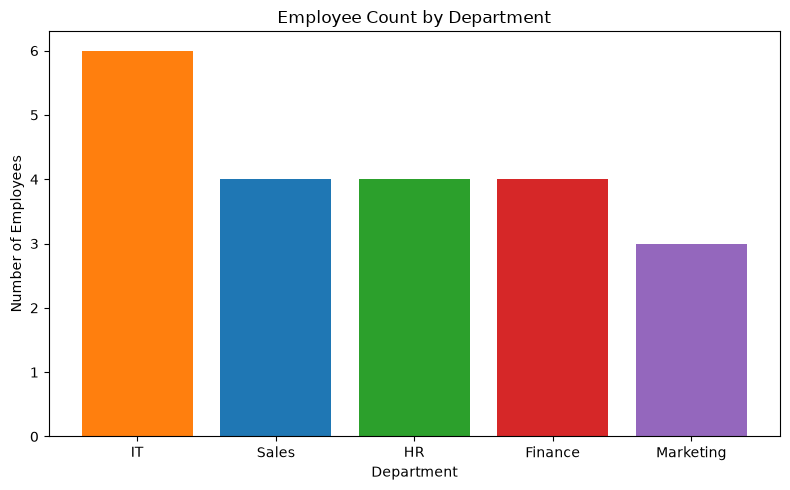

**Insight:** IT has the most employees (6) in this dataset.

In [19]:


counts = df["department"].value_counts().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
bar_colors = [department_colors[dept] for dept in counts.index]
ax.bar(counts.index, counts.values, color=bar_colors)

ax.set_title("Employee Count by Department")
ax.set_xlabel("Department")
ax.set_ylabel("Number of Employees")

top_department = counts.idxmax()
insight = (
    f"{top_department} has the most employees "
    f"({counts.max()}) in this dataset."
)

save_chart(fig, "employee_count_by_department.png", insight)

Int64


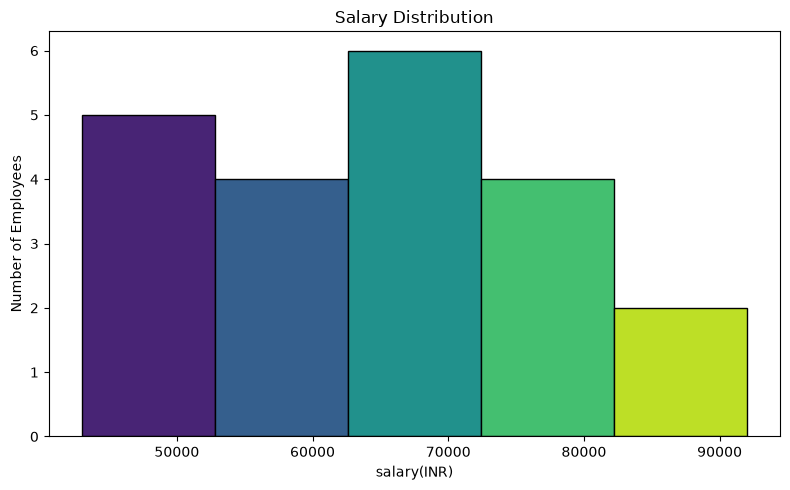

**Insight:** the most common salary distribution is between 62600.0 to 72400.0 

In [20]:
df["salary"] = (
    df["salary"]
    .astype("string")
    .str.replace(",", "", regex=False)
)
df["salary"] = pd.to_numeric(df["salary"], errors="coerce")
df["salary"] = df["salary"].fillna(df["salary"].median())

print(df["salary"].dtype)





# histogram of salaries
fig,ax = plt.subplots(figsize=(8,5))
counts,bins,patches = ax.hist(df["salary"],bins =5, edgecolor = "black" )
cmap = plt.cm.viridis
norm = plt.Normalize(bins[0],bins[-1])
for patch , left,right in zip(patches,bins[:-1],bins[1:]):
    middle_salary = (left+right)/2
    patch.set_facecolor(cmap(norm(middle_salary)))



ax.set_title("Salary Distribution")
ax.set_xlabel(f"salary({SALARY_UNIT})")
ax.set_ylabel(f"Number of Employees")

most_common_bin = bins[np.argmax(counts)]

insight = (f"the most common salary distribution is between {most_common_bin} to {bins[np.argmax(counts) + 1]} ")

save_chart(fig,"salary_distribution.png",insight)



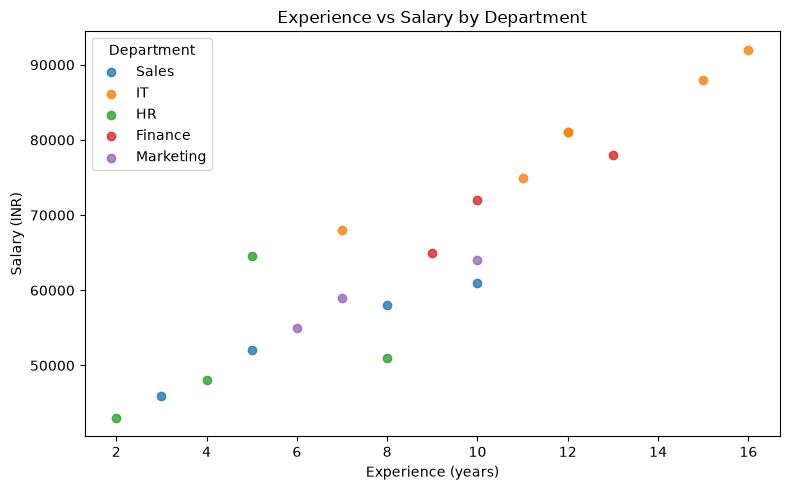

**Insight:** Experience and salary have a positive association in this sample (correlation: 0.92). This does not prove that one causes the other.

In [21]:

plot_data = df.dropna(
    subset=["experience_years", "salary", "department"]
)

fig, ax = plt.subplots(figsize=(8, 5))

for department in departments:
    rows = plot_data[plot_data["department"] == department]
    ax.scatter(
        rows["experience_years"],
        rows["salary"],
        color=department_colors[department],
        label=department,
        alpha=0.8
    )

ax.set_title("Experience vs Salary by Department")
ax.set_xlabel("Experience (years)")
ax.set_ylabel(f"Salary ({SALARY_UNIT})")
ax.legend(title="Department")

correlation = plot_data["experience_years"].corr(plot_data["salary"])
direction = "positive" if correlation >= 0 else "negative"
insight = (
    f"Experience and salary have a {direction} association "
    f"in this sample (correlation: {correlation:.2f}). "
    "This does not prove that one causes the other."
)

save_chart(fig, "experience_vs_salary.png", insight)

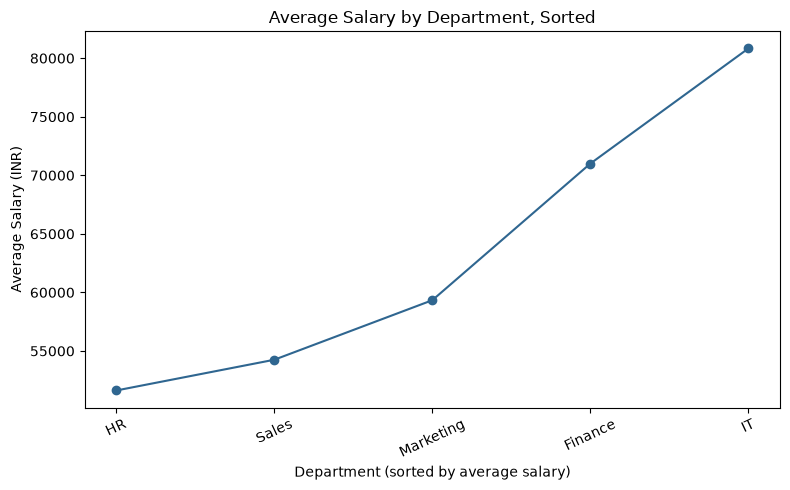

**Insight:** HR has the lowest average salary, while IT has the highest in this dataset.

In [22]:
# LINE CHART 
average_salary = (
    df.groupby("department")["salary"]
    .mean()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    average_salary.index,
    average_salary.values,
    color=MAIN_COLOR,
    marker="o"
)

ax.set_title("Average Salary by Department, Sorted")
ax.set_xlabel("Department (sorted by average salary)")
ax.set_ylabel(f"Average Salary ({SALARY_UNIT})")
ax.tick_params(axis="x", rotation=25)

lowest_department = average_salary.idxmin()
highest_department = average_salary.idxmax()

insight = (
    f"{lowest_department} has the lowest average salary, while "
    f"{highest_department} has the highest in this dataset."
)

save_chart(fig, "average_salary_sorted.png", insight)


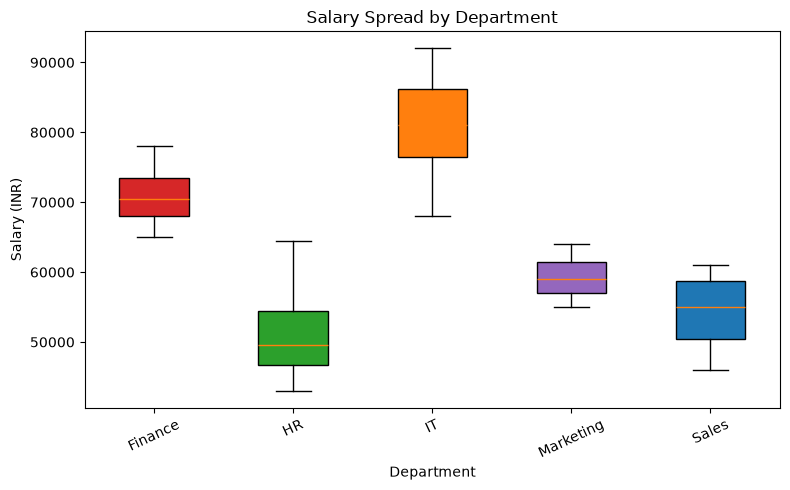

**Insight:** IT has the highest median salary; HR has the lowest.

In [23]:

# 5. BOX PLOT
box_departments = sorted(df["department"].dropna().unique())
box_data = [
    df.loc[df["department"] == department, "salary"].dropna()
    for department in box_departments
]

fig, ax = plt.subplots(figsize=(8, 5))
boxes = ax.boxplot(
    box_data,
    tick_labels=box_departments,
    patch_artist=True
)

for box, department in zip(boxes["boxes"], box_departments):
    box.set_facecolor(department_colors[department])

ax.set_title("Salary Spread by Department")
ax.set_xlabel("Department")
ax.set_ylabel(f"Salary ({SALARY_UNIT})")
ax.tick_params(axis="x", rotation=25)

department_medians = df.groupby("department")["salary"].median()
highest_median_dept = department_medians.idxmax()
lowest_median_dept = department_medians.idxmin()

insight = (
    f"{highest_median_dept} has the highest median salary; "
    f"{lowest_median_dept} has the lowest."
)

save_chart(fig, "salary_boxplot_by_department.png", insight)


# Findings Summary

## Problem
This analysis explores how employee counts and salaries differ across departments, whether experience is associated with salary, and where attrition appears in the sample.

## Data
The CSV contains 20 employee records across five departments. It includes department, salary, experience, city, age, and attrition. The dataset is generated practice data, not real-world employee data.

## Three key insights
1. IT has the most employees (5); Marketing has the fewest (3). The other departments have 4 employees each.
2. Average salary is highest in IT (INR 80,800) and lowest in HR (INR 51,500). The missing salary was filled with the overall median of INR 64,000.
3. Marketing has the highest recorded attrition in this sample: 2 of 3 employees (about 67%). Experience and salary also show a positive association (correlation about 0.91), but that does not prove experience causes higher salary.

## Recommendations
1. Review salary differences by job role and seniority before making compensation decisions; department averages alone do not explain why salaries differ.
2. Investigate why the two Marketing records are marked with attrition, and check a larger dataset before deciding on retention actions.

## Limitations
This is a small, generated dataset with only 20 records, so its patterns cannot be generalized to a real workforce. The missing salary was filled with the median, and employee 1019’s experience was set to 7; that value should be verified because it was manually supplied. The data has no date column, so the sorted department salary line chart is not a time trend.